In [ ]:
!pip install -q kagglehub scikit-learn pandas matplotlib

In [ ]:
import os, json, time, hashlib, shutil, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

TEAM_ID = "34"
SEED = 42
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
IMAGE_SIZE = 224
BATCH_SIZE = 32
DATA_DIR = "data/brain-tumor-mri-dataset"
OUT_DIR = "outputs_tensorflow_aug"
MODEL_DIR = "model"

for d in ("data", OUT_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices("GPU"))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
src = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
shutil.copytree(src, DATA_DIR, dirs_exist_ok=True)
print(os.listdir(DATA_DIR))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
['Testing', 'Training']


In [ ]:
rows = []
for root, _, files in os.walk(DATA_DIR):
    label = os.path.basename(root)
    if label in CLASS_NAMES:
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                rows.append({"path": os.path.join(root, f).replace(os.sep, "/"), "label": label})

df = pd.DataFrame(rows).sort_values("path").reset_index(drop=True)

def file_md5(p):
    with open(p, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

df["md5"] = df["path"].apply(file_md5)
print(df["label"].value_counts().reindex(CLASS_NAMES))
n_dup = int(df.duplicated("md5").sum())
df = df.drop_duplicates("md5").reset_index(drop=True)
print("duplicates removed:", n_dup)
print(df["label"].value_counts().reindex(CLASS_NAMES))

assert sorted(df["label"].unique()) == sorted(CLASS_NAMES)
df["label_idx"] = df["label"].map({c: i for i, c in enumerate(CLASS_NAMES)})
print("total images:", len(df))

label
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800
Name: count, dtype: int64
duplicates removed: 187
label
glioma        1786
meningioma    1784
notumor       1681
pituitary     1762
Name: count, dtype: int64
total images: 7013


In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label_idx"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label_idx"], random_state=SEED)

train_df = train_df.sort_values("path").reset_index(drop=True).assign(split="train")
val_df = val_df.sort_values("path").reset_index(drop=True).assign(split="val")
test_df = test_df.sort_values("path").reset_index(drop=True).assign(split="test")

assert not set(train_df["path"]) & set(val_df["path"])
assert not set(train_df["path"]) & set(test_df["path"])
assert not set(val_df["path"]) & set(test_df["path"])
assert not set(train_df["md5"]) & set(val_df["md5"])
assert not set(train_df["md5"]) & set(test_df["md5"])
assert not set(val_df["md5"]) & set(test_df["md5"])

manifest = pd.concat([train_df, val_df, test_df], ignore_index=True)
manifest[["path", "label", "label_idx", "split", "md5"]].to_csv(f"{OUT_DIR}/split_manifest.csv", index=False)

counts = pd.crosstab(manifest["label"], manifest["split"])[["train", "val", "test"]].loc[CLASS_NAMES]
counts.loc["total"] = counts.sum()
counts.to_csv(f"{OUT_DIR}/split_counts.csv")
print(counts)

split       train   val  test
label                        
glioma       1250   268   268
meningioma   1249   267   268
notumor      1177   252   252
pituitary    1233   265   264
total        4909  1052  1052


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_raw(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, (IMAGE_SIZE, IMAGE_SIZE), method="bilinear")

def load_example(path, label):
    return preprocess_input(load_raw(path)), label

AUG = {
    "rotation_deg": 10,
    "translation_frac": 0.05,
    "zoom_frac": 0.05,
    "fill": "constant black (0), matches the MRI background",
    "horizontal_flip": False,
    "vertical_flip": False,
    "brightness_contrast_noise": False,
    "applied_to": "training set only (validation and test are never augmented)",
    "rationale": "small positioning variations only; no flips, no intensity changes, no elastic or large distortions that could alter tumor shape, location or appearance",
}
augmenter = tf.keras.Sequential([
    layers.RandomRotation(AUG["rotation_deg"] / 360.0, fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomTranslation(AUG["translation_frac"], AUG["translation_frac"], fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomZoom(AUG["zoom_frac"], fill_mode="constant", fill_value=0.0, seed=SEED),
], name="train_augmentation")

def make_ds(frame, shuffle, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label_idx"].values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED)
    if augment:
        ds = ds.map(lambda p, y: (load_raw(p), y), num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
        ds = ds.map(lambda x, y: (preprocess_input(augmenter(x, training=True)), y), num_parallel_calls=AUTOTUNE)
        return ds.prefetch(AUTOTUNE)
    return ds.map(load_example, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, True, augment=True)
val_ds = make_ds(val_df, False)
test_ds = make_ds(test_df, False)
y_val = val_df["label_idx"].values
y_test = test_df["label_idx"].values

preprocessing_spec = {
    "image_size": IMAGE_SIZE,
    "color_mode": "RGB",
    "resize_method": "bilinear",
    "tensorflow_normalization": "tf.keras.applications.resnet50.preprocess_input (RGB to BGR, subtract ImageNet mean [103.939, 116.779, 123.68], no scaling)",
    "pytorch_equivalent_normalization": {"scale": "divide by 255", "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
    "augmentation": AUG,
    "class_names": CLASS_NAMES,
    "split": {"train": 0.70, "val": 0.15, "test": 0.15, "stratified": True, "seed": SEED, "duplicates_removed": n_dup, "manifest": "split_manifest.csv"},
    "batch_size": BATCH_SIZE,
}
with open(f"{OUT_DIR}/preprocessing_spec.json", "w") as fh:
    json.dump(preprocessing_spec, fh, indent=2)
print(json.dumps(preprocessing_spec, indent=2))

{
  "image_size": 224,
  "color_mode": "RGB",
  "resize_method": "bilinear",
  "tensorflow_normalization": "tf.keras.applications.resnet50.preprocess_input (RGB to BGR, subtract ImageNet mean [103.939, 116.779, 123.68], no scaling)",
  "pytorch_equivalent_normalization": {
    "scale": "divide by 255",
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "augmentation": {
    "rotation_deg": 10,
    "translation_frac": 0.05,
    "zoom_frac": 0.05,
    "fill": "constant black (0), matches the MRI background",
    "horizontal_flip": false,
    "vertical_flip": false,
    "brightness_contrast_noise": false,
    "applied_to": "training set only (validation and test are never augmented)",
    "rationale": "small positioning variations only; no flips, no intensity changes, no elastic or large distortions that could alter tumor shape, location or appearance"
  },
  "class_names": [
    "glioma",
    "meningioma",
    "notum

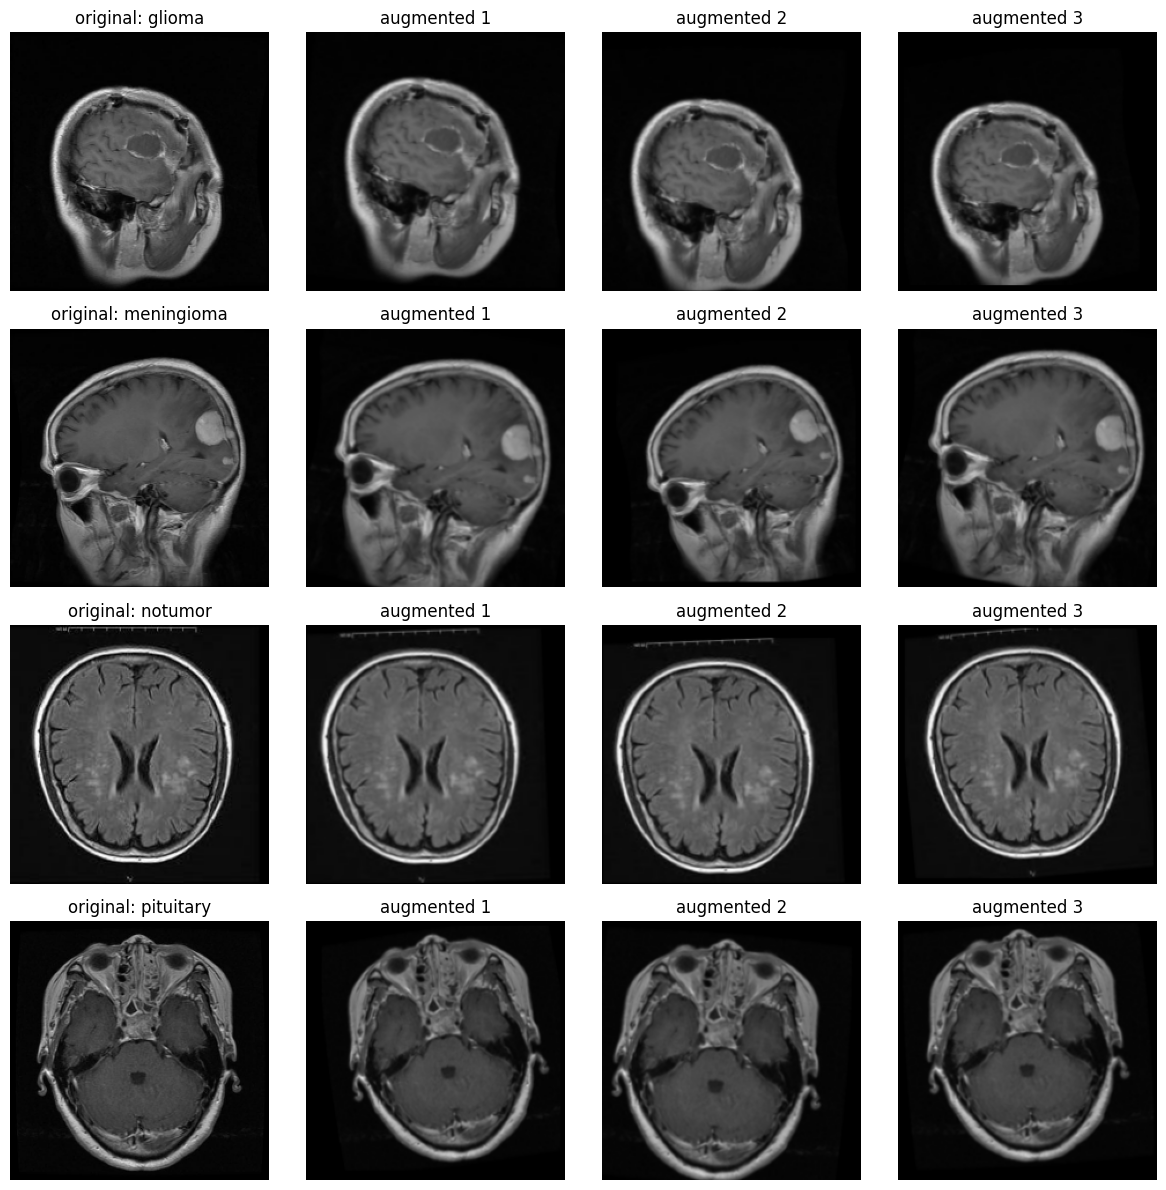

In [ ]:

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 12))
for r, name in enumerate(CLASS_NAMES):
    row = train_df[train_df["label"] == name].sample(1, random_state=SEED).iloc[0]
    raw = load_raw(row["path"])
    axes[r, 0].imshow(raw.numpy().astype("uint8"))
    axes[r, 0].set_title(f"original: {name}")
    for c in range(1, 4):
        aug_img = augmenter(tf.expand_dims(raw, 0), training=True)[0].numpy().astype("uint8")
        axes[r, c].imshow(aug_img)
        axes[r, c].set_title(f"augmented {c}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/sample_augmentations.png", dpi=150)
plt.show()


In [ ]:
base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dropout(0.3)(x)
logits = layers.Dense(len(CLASS_NAMES), name="logits")(x)
probs = layers.Activation("softmax", name="probs")(logits)
model = models.Model(base.input, probs)

def evaluate(m, ds, y_true, loss_name="test_loss"):
    loss, acc = m.evaluate(ds, verbose=0)
    prob = m.predict(ds, verbose=0)
    pred = prob.argmax(axis=1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    metrics = {
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision_macro": float(p),
        "recall_macro": float(r),
        "f1_macro": float(f),
        loss_name: float(loss),
    }
    return metrics, pred, prob

for layer in base.layers:
    layer.trainable = False

PHASE1_LR = 1e-3
PHASE1_EPOCHS = 10
model.compile(optimizer=tf.keras.optimizers.Adam(PHASE1_LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE1_EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1)],
)
phase1_time = time.time() - t0

n1 = len(h1.history["loss"])
best1 = int(np.argmin(h1.history["val_loss"])) + 1
print(f"Phase 1: ran {n1} epochs; best epoch = {best1} (val_loss={min(h1.history['val_loss']):.4f}); weights restored from epoch {best1}")
print("Note: the last logged epoch can differ from the metrics below because the best epoch is restored,")
print("and logged train metrics are running averages with dropout active.")

frozen_val_metrics, _, _ = evaluate(model, val_ds, y_val, loss_name="val_loss")
print(frozen_val_metrics)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 75s 399ms/step - accuracy: 0.7081 - loss: 0.7636 - val_accuracy: 0.8384 - val_loss: 0.4080
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 51s 327ms/step - accuracy: 0.8366 - loss: 0.4374 - val_accuracy: 0.8793 - val_loss: 0.3250
Epoch 3/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 53s 342ms/step - accuracy: 0.8556 - loss: 0.3805 - val_accuracy: 0.8764 - val_loss: 0.3328
Epoch 4/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 55s 351ms/step - accuracy: 0.8647 - loss: 0.3524 - val_accuracy: 0.8793 - val_loss: 0.3091
Epoch 5/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 54s 349ms/step - accuracy: 0.8888 - loss: 0.3172 - val_accuracy: 0.8859 - val_loss: 0.2922
Epoch 6/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 80s 338ms/step - accuracy: 0.8835 - loss: 0.2998 - val_accuracy: 0.8584 - val_loss: 0.3288
Epoch 7/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 340ms/step - accuracy: 0.8953 - loss: 0.2857 - val_accuracy: 0.8926 - val_loss: 0.2686
Epoch 8/10
154/154 ━━━━━━━━━━━━━

In [ ]:
UNFREEZE_LAST = 30
PHASE2_LR = 1e-5
PHASE2_EPOCHS = 20

for layer in base.layers[-UNFREEZE_LAST:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(PHASE2_LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()

h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=n1,
    epochs=n1 + PHASE2_EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1)],
)
phase2_time = time.time() - t0
n2 = len(h2.history["loss"])
best2 = n1 + int(np.argmin(h2.history["val_loss"])) + 1
print(f"Phase 2: epochs {n1 + 1}-{n1 + n2}; best epoch = {best2} (val_loss={min(h2.history['val_loss']):.4f}); weights restored from epoch {best2}")
print(phase1_time, phase2_time)

Epoch 11/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 81s 420ms/step - accuracy: 0.9049 - loss: 0.2534 - val_accuracy: 0.9163 - val_loss: 0.2411
Epoch 12/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 61s 339ms/step - accuracy: 0.9287 - loss: 0.1875 - val_accuracy: 0.9297 - val_loss: 0.2198
Epoch 13/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 81s 335ms/step - accuracy: 0.9491 - loss: 0.1391 - val_accuracy: 0.9154 - val_loss: 0.2628
Epoch 14/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 338ms/step - accuracy: 0.9546 - loss: 0.1175 - val_accuracy: 0.9249 - val_loss: 0.2043
Epoch 15/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 53s 338ms/step - accuracy: 0.9662 - loss: 0.0899 - val_accuracy: 0.9316 - val_loss: 0.1949
Epoch 16/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 53s 341ms/step - accuracy: 0.9756 - loss: 0.0721 - val_accuracy: 0.9240 - val_loss: 0.2306
Epoch 17/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 53s 343ms/step - accuracy: 0.9804 - loss: 0.0577 - val_accuracy: 0.9420 - val_loss: 0.1820
Epoch 18/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 342ms/step - accuracy: 0.9825 -

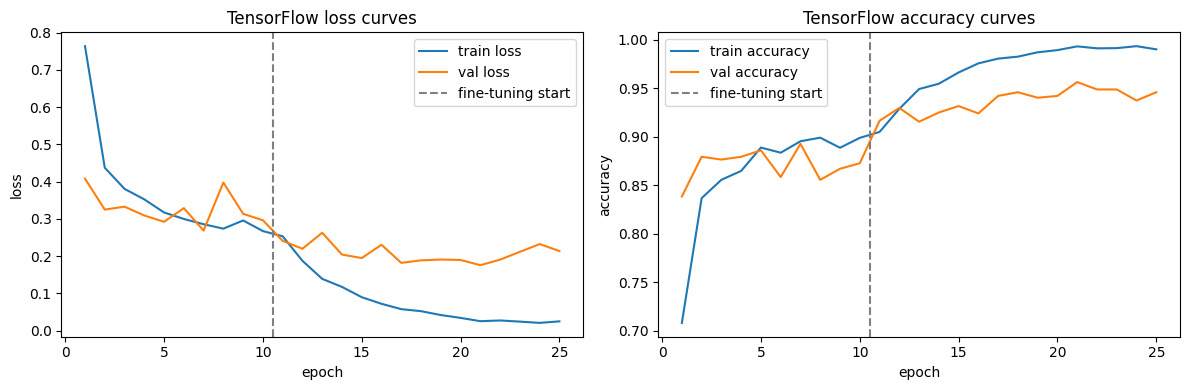

model/model_34.keras 210.548227 MB


In [ ]:
hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
hist_df = pd.DataFrame(hist)
hist_df.insert(0, "epoch", np.arange(1, len(hist_df) + 1))
hist_df.insert(1, "phase", ["frozen"] * len(h1.history["loss"]) + ["fine_tune"] * len(h2.history["loss"]))
hist_df.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
epochs_axis = np.arange(1, len(hist["loss"]) + 1)
switch = len(h1.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, hist["loss"], label="train loss")
axes[0].plot(epochs_axis, hist["val_loss"], label="val loss")
axes[0].axvline(switch + 0.5, color="gray", linestyle="--", label="fine-tuning start")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("TensorFlow loss curves")
axes[0].legend()
axes[1].plot(epochs_axis, hist["accuracy"], label="train accuracy")
axes[1].plot(epochs_axis, hist["val_accuracy"], label="val accuracy")
axes[1].axvline(switch + 0.5, color="gray", linestyle="--", label="fine-tuning start")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].set_title("TensorFlow accuracy curves")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves_tensorflow.png", dpi=150)
plt.show()

MODEL_PATH = f"{MODEL_DIR}/model_{TEAM_ID}.keras"
model.save(MODEL_PATH)
reloaded = tf.keras.models.load_model(MODEL_PATH)
sample = next(iter(val_ds))[0]
assert np.allclose(model.predict(sample, verbose=0), reloaded.predict(sample, verbose=0), atol=1e-5)
print(MODEL_PATH, os.path.getsize(MODEL_PATH) / 1e6, "MB")

{'accuracy': 0.9562737642585551, 'precision_macro': 0.9567199719300364, 'recall_macro': 0.9566116670501335, 'f1_macro': 0.9565355767689225, 'val_loss': 0.175809845328331}
{'accuracy': 0.9638783269961977, 'precision_macro': 0.9642461699461122, 'recall_macro': 0.9641686050268139, 'f1_macro': 0.9641349578361131, 'test_loss': 0.15984897315502167}
              precision    recall  f1-score   support

      glioma     0.9517    0.9552    0.9534       268
  meningioma     0.9506    0.9328    0.9416       268
     notumor     0.9880    0.9762    0.9820       252
   pituitary     0.9668    0.9924    0.9794       264

    accuracy                         0.9639      1052
   macro avg     0.9642    0.9642    0.9641      1052
weighted avg     0.9639    0.9639    0.9638      1052



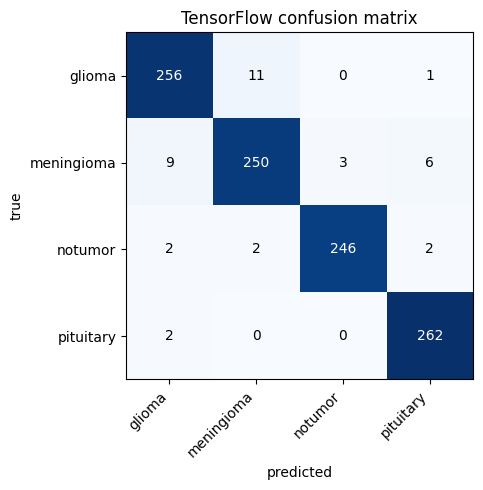

In [ ]:
fine_tuned_val_metrics, _, _ = evaluate(model, val_ds, y_val, loss_name="val_loss")
print(fine_tuned_val_metrics)
final_metrics, y_pred, y_prob = evaluate(model, test_ds, y_test)
print(final_metrics)

report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
print(report)
with open(f"{OUT_DIR}/classification_report_tensorflow.txt", "w") as fh:
    fh.write(report)

cm = confusion_matrix(y_test, y_pred, labels=list(range(len(CLASS_NAMES))))
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{OUT_DIR}/confusion_matrix_tensorflow.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("TensorFlow confusion matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix_tensorflow.png", dpi=150)
plt.show()

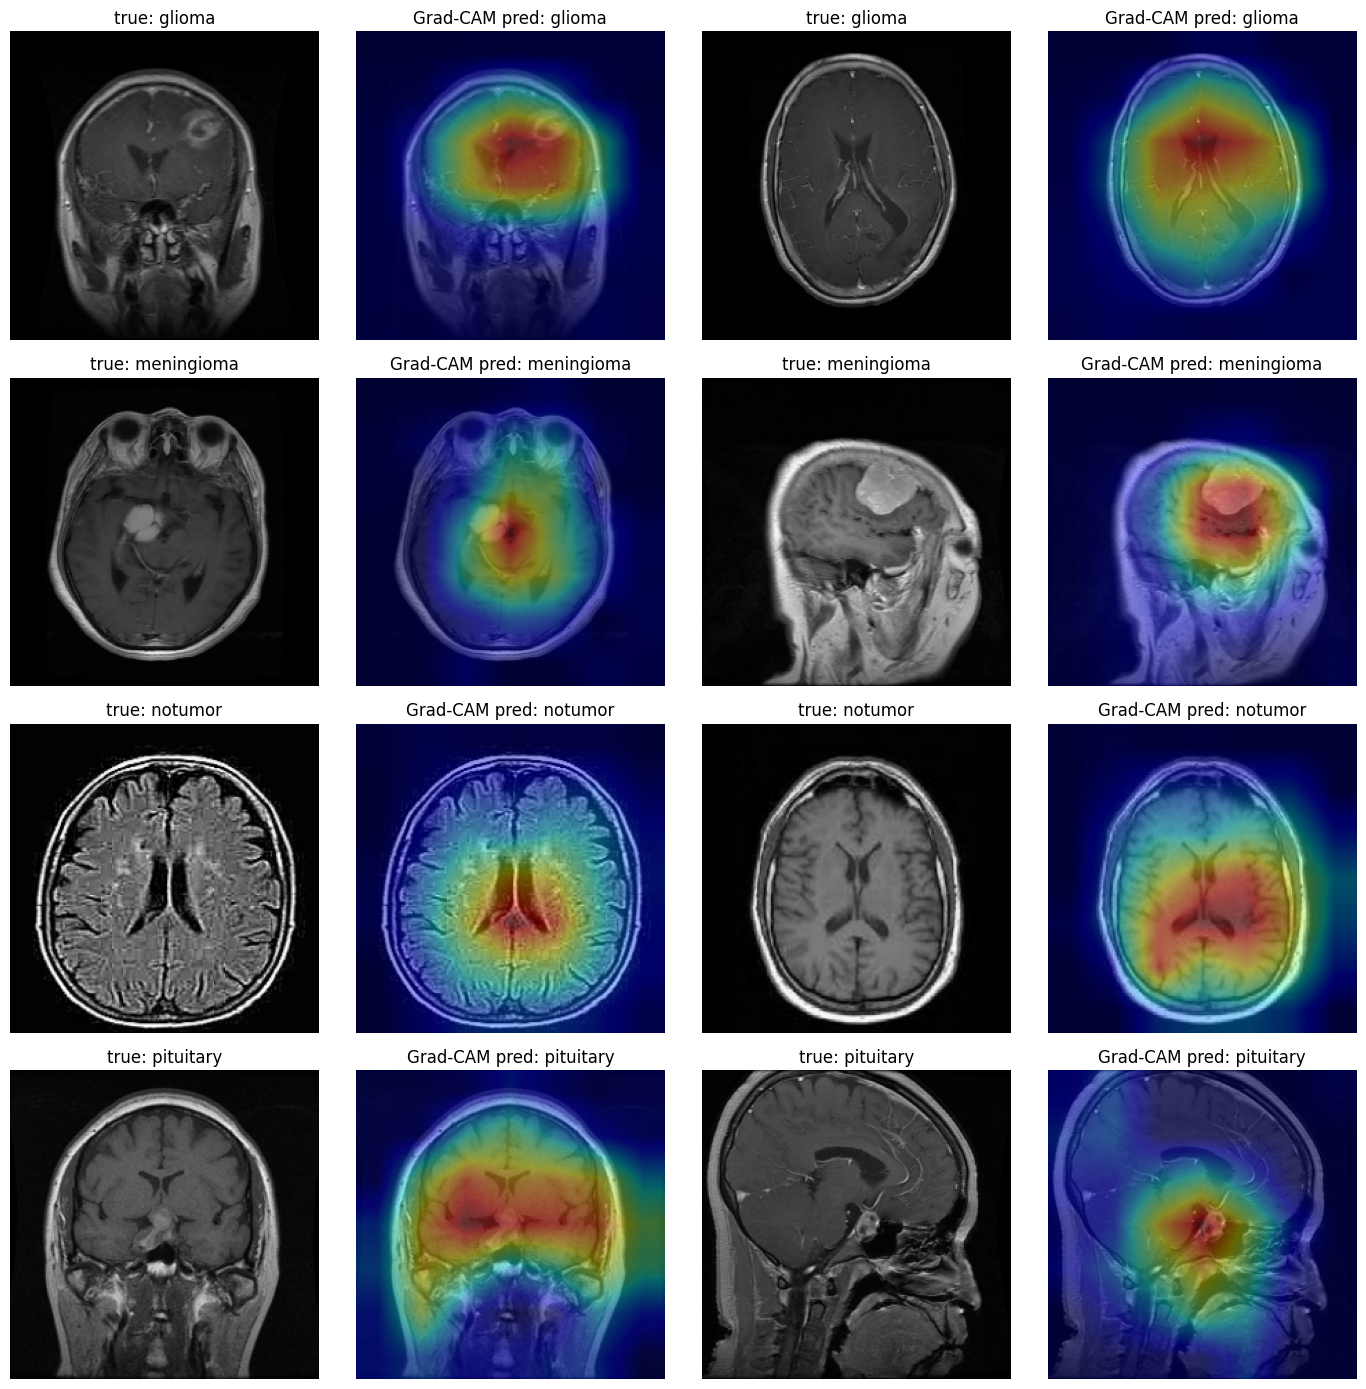

In [ ]:
grad_model = models.Model(model.inputs, [model.get_layer("conv5_block3_out").output, model.get_layer("logits").output])

def gradcam(raw):
    x = preprocess_input(tf.expand_dims(raw, 0))
    with tf.GradientTape() as tape:
        conv, out = grad_model(x, training=False)
        idx = tf.argmax(out[0])
        score = out[0, idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., tf.newaxis], (IMAGE_SIZE, IMAGE_SIZE))[..., 0].numpy()
    return cam, int(idx)

samples = pd.concat([test_df[test_df["label_idx"] == i].sample(2, random_state=SEED) for i in range(len(CLASS_NAMES))])

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(14, 14))
for k, (_, row) in enumerate(samples.iterrows()):
    r, c = k // 2, (k % 2) * 2
    raw = load_raw(row["path"])
    cam, pred_idx = gradcam(raw)
    img = raw.numpy().astype("uint8")
    axes[r, c].imshow(img)
    axes[r, c].set_title(f"true: {row['label']}")
    axes[r, c + 1].imshow(img)
    axes[r, c + 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, c + 1].set_title(f"Grad-CAM pred: {CLASS_NAMES[pred_idx]}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gradcam_tensorflow.png", dpi=150)
plt.show()

In [ ]:
single = next(iter(val_ds))[0][:1]
with tf.device("/CPU:0"):
    for _ in range(5):
        reloaded(single, training=False)
    t0 = time.time()
    for _ in range(50):
        reloaded(single, training=False).numpy()
    latency_ms = (time.time() - t0) / 50 * 1000

config = {
    "framework": "tensorflow",
    "architecture": "ResNet50 (ImageNet pretrained)",
    "head": "GlobalAveragePooling2D, Dropout(0.3), Dense(4), Softmax",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "seed": SEED,
    "phase1_frozen_backbone": {"learning_rate": PHASE1_LR, "max_epochs": PHASE1_EPOCHS, "epochs_run": n1, "epoch_range": [1, n1], "best_epoch": best1, "early_stopping_patience": 3, "training_time_sec": phase1_time},
    "phase2_fine_tuning": {"learning_rate": PHASE2_LR, "max_epochs": PHASE2_EPOCHS, "epochs_run": n2, "epoch_range": [n1 + 1, n1 + n2], "best_epoch": best2, "early_stopping_patience": 4, "unfrozen_last_layers": UNFREEZE_LAST, "batchnorm_frozen": True, "training_time_sec": phase2_time},
    "total_training_time_sec": phase1_time + phase2_time,
    "split_counts": {s: int((manifest["split"] == s).sum()) for s in ("train", "val", "test")},
    "augmentation": AUG,
}
results = {
    "config": config,
    "frozen_backbone_val_metrics": frozen_val_metrics,
    "fine_tuned_val_metrics": fine_tuned_val_metrics,
    "fine_tuned_test_metrics": final_metrics,
    "model_size_mb": os.path.getsize(MODEL_PATH) / 1e6,
    "cpu_inference_latency_ms_single_image": latency_ms,
    "trainable_params": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
    "total_params": int(model.count_params()),
}
with open(f"{OUT_DIR}/tensorflow_results.json", "w") as fh:
    json.dump(results, fh, indent=2)
print(json.dumps(results, indent=2))
print(sorted(os.listdir(OUT_DIR)))

{
  "config": {
    "framework": "tensorflow",
    "architecture": "ResNet50 (ImageNet pretrained)",
    "head": "GlobalAveragePooling2D, Dropout(0.3), Dense(4), Softmax",
    "image_size": 224,
    "batch_size": 32,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "seed": 42,
    "phase1_frozen_backbone": {
      "learning_rate": 0.001,
      "max_epochs": 10,
      "epochs_run": 10,
      "epoch_range": [
        1,
        10
      ],
      "best_epoch": 7,
      "early_stopping_patience": 3,
      "training_time_sec": 638.751068353653
    },
    "phase2_fine_tuning": {
      "learning_rate": 1e-05,
      "max_epochs": 20,
      "epochs_run": 15,
      "epoch_range": [
        11,
        25
      ],
      "best_epoch": 21,
      "early_stopping_patience": 4,
      "unfrozen_last_layers": 30,
      "batchnorm_frozen": true,
      "training_time_sec": 973.8903474807739
    },
    "total_training_time_sec": 1612.6414158344269,
    "split_counts": {
      "tr

In [ ]:
import shutil
from google.colab import files
shutil.make_archive("/content/outputs_tensorflow_aug", "zip", "/content/outputs_tensorflow_aug")
files.download("/content/outputs_tensorflow_aug.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>